# Chapitre 6 · Simulations, probabilités, concurrence et pandas

Ce notebook prolonge le chapitre 5. Il suppose connus les tableaux, les axes, les masques, la vectorisation et les premières lois de probabilité. Les nouvelles notions sont développées au moment où elles servent.

Le parcours suit les 59 diapositives : trajectoires cumulées et quantiles empiriques, lois de Poisson et exponentielle, bootstrap, concurrence et premières tables pandas. Des compléments pandas restent à la fin.

Pour chaque exercice, écrire les étapes, essayer le programme puis lire la correction. Les données sont fictives. Tous les exemples fonctionnent hors ligne.

## Environnement

~~~text
python -m pip install numpy scipy pandas matplotlib
~~~

Les appels de concurrence appartiennent à la bibliothèque standard. Le notebook utilise await ; les processus passent par un programme autonome fourni.

In [1]:
import numpy as np
import scipy
import pandas as pd
from scipy import stats
import matplotlib.pyplot as plt
print("NumPy",np.__version__,"SciPy",scipy.__version__,"pandas",pd.__version__)
plt.rcParams.update({"figure.dpi":110,"font.size":11,
    "axes.spines.top":False,"axes.spines.right":False,
    "axes.grid":True,"grid.alpha":.15,
    "figure.constrained_layout.use":True})
burgundy, ink, slate = "#8C1515", "#2E2D29", "#686868"

NumPy 2.3.5 SciPy 1.18.1 pandas 2.2.3


### 2. Le programme du chapitre

Le chapitre prolonge les acquis du chapitre 5. Nouvelles opérations NumPy : cumprod, calcul sur des trajectoires, sort, searchsorted et quantile. Nouvelles méthodes SciPy : modèles de Poisson et exponentiel, puis rééchantillonnage bootstrap. Les sections concurrence et introduction à pandas suivent.

## 1. Nouveaux calculs NumPy et SciPy

### 3. Problème 1 : un capital avec des variations successives

Entrées : capital initial 100 €, quatre scénarios et trois jours de variations : A=[0.10,-0.10,0], B=[-0.10,0,0.10], C=[0.02,0.02,0.02], D=[-0.05,-0.05,-0.05]. Sortie : le capital après chaque jour. Modèle fictif, sans frais.

| Scénario | Jour 1 | Jour 2 | Jour 3 |
| --- | --- | --- | --- |
| A | +10 % | −10 % | 0 % |
| B | −10 % | 0 % | +10 % |
| C | +2 % | +2 % | +2 % |
| D | −5 % | −5 % | −5 % |

### 4. La valeur du jour dépend de celle de la veille

La formule récurrente est C_t=C_(t-1)*(1+r_t), avec C_0=100. Trace A : 100,110,99,99. Ajouter +10 % et -10 % donnerait à tort zéro variation totale. Le produit cumulé donne les valeurs successives.

$C_0=100$ et $C_t=C_{t-1}(1+r_t)$.

Trace A : 100 × 1,10 = 110, puis 110 × 0,90 = 99. Le second pourcentage s'applique au capital courant.

### 5. np.cumprod conserve les produits intermédiaires

prod renvoie un produit total. cumprod conserve les produits intermédiaires : [1.10,0.99,0.99]. Sur un tableau (scénarios,jours), axis=1 réalise ce calcul le long des jours, indépendamment dans chaque ligne. La forme ne change pas.

In [2]:
import numpy as np
facteurs = np.array([1.10, 0.90, 1.00])
print(np.prod(facteurs))       # 0.99, à l'arrondi près
print(np.cumprod(facteurs))    # [1.10 0.99 0.99]

0.9900000000000001
[1.1  0.99 0.99]


### 6. Exercice : les quatre trajectoires en une opération

Exercice : construire les facteurs 1+variations, utiliser cumprod sur les jours et multiplier par 100. Extraire la dernière colonne avec [:,-1]. Tracer le scénario D. Expliquer pourquoi sommer les variations donne un autre calcul.

**Votre pseudocode, vos explications et votre trace**

Écrire ici les étapes et une vérification sur un petit cas.

In [3]:
variations = np.array([
    [ .10, -.10,  .00],
    [-.10,  .00,  .10],
    [ .02,  .02,  .02],
    [-.05, -.05, -.05]
])

In [4]:
# Votre essai : pseudocode, puis programme et vérification.

### 7. Correction : quatre calculs indépendants

Correction : 100*np.cumprod(1+variations,axis=1), puis [:,-1]. Capitaux finaux 99,99,106.1208,85.7375 €. La trace de D est 100,95,90.25,85.7375. Ne pas cumuler entre scénarios.

In [5]:
trajectoires = 100 * np.cumprod(1 + variations, axis=1)
capitaux_finaux = trajectoires[:, -1]
print(np.round(capitaux_finaux, 2))  # [99. 99. 106.12 85.74]

[ 99.    99.   106.12  85.74]


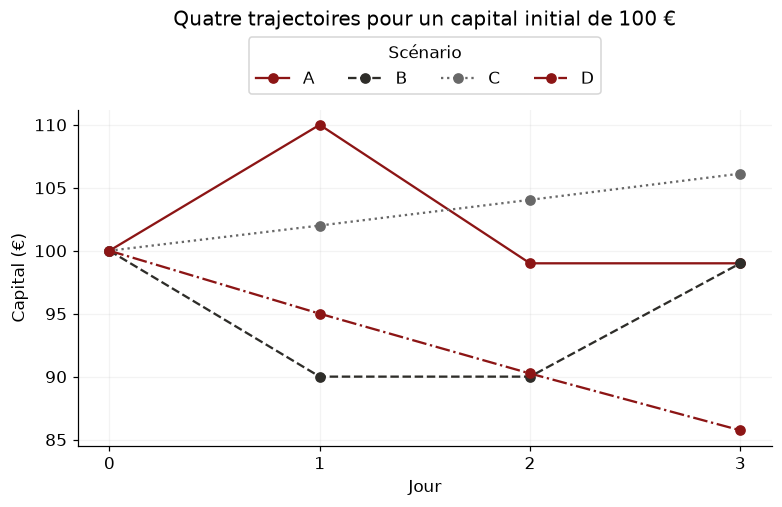

In [6]:
fig, ax = plt.subplots(figsize=(7,4.5))
jours = np.arange(4)
for i,(nom,style,couleur) in enumerate([
    ("A","-",burgundy),("B","--",ink),("C",":",slate),("D","-.",burgundy)]):
    ax.plot(jours,np.r_[100,trajectoires[i]],style,marker="o",color=couleur,label=nom)
ax.set(title="Quatre trajectoires pour un capital initial de 100 €",
       xlabel="Jour",ylabel="Capital (€)",xticks=jours)
ax.legend(title="Scénario",ncol=4,loc="lower center",bbox_to_anchor=(.5,1.02))
ax.set_title("Quatre trajectoires pour un capital initial de 100 €",pad=55)
plt.show()

### 8. Un lot de 10 000 trajectoires sur vingt jours

Le nouveau calcul porte sur un lot (10000,20) de trajectoires, et non sur une simple liste de gains. choice tire -0.02 ou 0.01 avec probabilités 0.3 et 0.7. Les jours et scénarios sont indépendants selon le modèle. cumprod suit axis=1. fin a 10000 valeurs. Chaque tableau float64 de 200000 cases occupe 1.6 Mo décimaux.

In [7]:
rng = np.random.default_rng(2026)
tirages = rng.choice(
    [-0.02, 0.01], size=(10_000, 20), p=[0.3, 0.7])
capitaux = 100 * np.cumprod(1 + tirages, axis=1)
fin = capitaux[:, -1]
print(tirages.shape, fin.shape)  # (10000, 20) (10000,)

(10000, 20) (10000,)


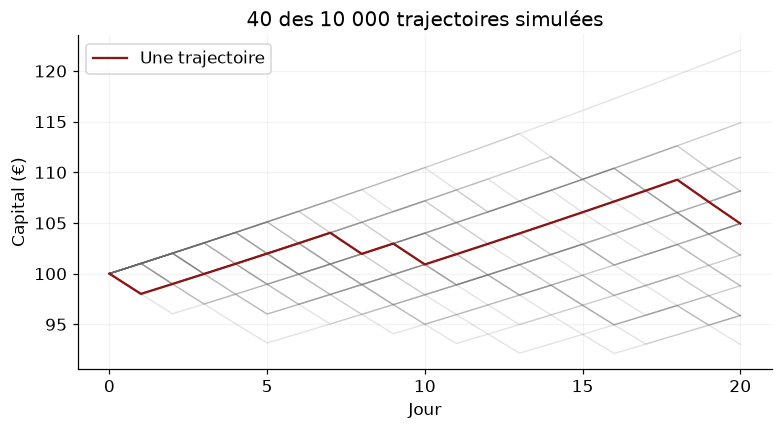

In [8]:
fig, ax = plt.subplots(figsize=(7,3.8))
for ligne in capitaux[:40]:
    ax.plot(np.arange(21),np.r_[100,ligne],color=slate,alpha=.18,lw=.9)
ax.plot(np.arange(21),np.r_[100,capitaux[0]],color=burgundy,label="Une trajectoire")
ax.set(title="40 des 10 000 trajectoires simulées",
       xlabel="Jour",ylabel="Capital (€)",xticks=[0,5,10,15,20])
ax.legend()
plt.show()

### 9. Une probabilité empirique à partir des capitaux triés

Probabilité empirique : compter les cas, diviser par leur nombre. Dans [90,95,100,110,120], searchsorted(...,100,side='left') rend 2, soit 2/5=0.4 de valeurs strictement inférieures à 100. Le tableau doit déjà être trié. Avec side='right', on compterait aussi les valeurs égales.

In [9]:
exemple_trie = np.array([90, 95, 100, 110, 120])
position = np.searchsorted(exemple_trie, 100, side="left")
print(position, position / len(exemple_trie))  # 2 0.4

2 0.4


### 10. Exercice : risque de perte et quantiles empiriques

Exercice : trier fin avec np.sort, utiliser searchsorted(...,100,side='left') puis diviser par len(fin). Calculer np.quantile(fin,[.05,.5,.95]). Un quantile est une valeur du capital, pas une probabilité ni une borne garantie. Par défaut, l'indice théorique vaut (n-1)*q ; une position non entière conduit à une interpolation linéaire.

**Votre pseudocode, vos explications et votre trace**

Écrire ici les étapes et une vérification sur un petit cas.

In [10]:
# Votre essai : pseudocode, puis programme et vérification.

### 11. Correction : une distribution de résultats

Correction : proportion de perte 0.3974 ; quantiles [93.01859873,101.82529738,111.46578564]. Le capital a une distribution discrète et les égalités peuvent donner plus de 5 % des observations au niveau du quantile ou en dessous. Ce seuil dépend du modèle. Tri O(N log N), puis recherche O(log N). Pour un seul seuil, le masque est plus simple et O(N).

In [11]:
tries = np.sort(fin)
proba_perte = np.searchsorted(tries, 100, side="left") / len(fin)
quantiles = np.quantile(fin, [0.05, 0.50, 0.95])
print(proba_perte)          # 0.3974
print(np.round(quantiles, 2)) # [93.02 101.83 111.47]

0.3974
[ 93.02 101.83 111.47]


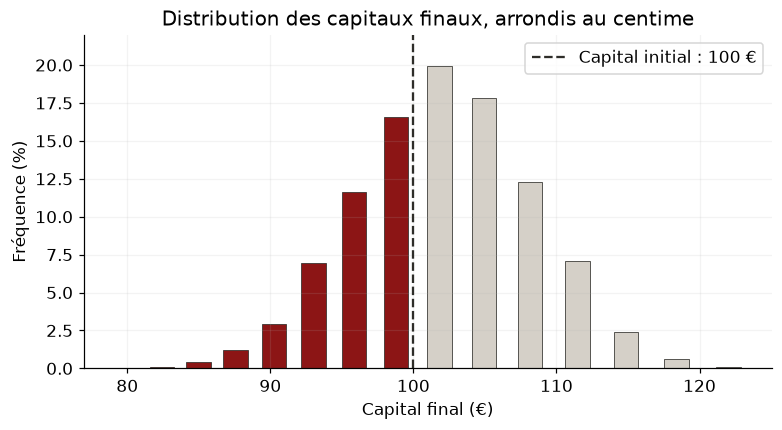

In [12]:
valeurs,effectifs = np.unique(np.round(fin,2),return_counts=True)
fig, ax = plt.subplots(figsize=(7,3.8))
couleurs = [burgundy if x<100 else "#D5D0C8" for x in valeurs]
ax.bar(valeurs,100*effectifs/len(fin),width=1.7,color=couleurs,edgecolor=ink,lw=.5)
ax.axvline(100,color=ink,ls="--",label="Capital initial : 100 €")
ax.set(title="Distribution des capitaux finaux, arrondis au centime",
       xlabel="Capital final (€)",ylabel="Fréquence (%)",ylim=(0,22))
ax.legend()
plt.show()

La distribution est discrète : les égalités forment des paliers. Un quantile empirique n'isole pas nécessairement exactement 5 % des observations. Pour un seul seuil, un masque est simple et coûte O(N). Le tri coûte O(N log N), puis chaque recherche supplémentaire coûte O(log N).

### 12. Problème 2 : combien d'appels peut-on absorber ?

Problème : dimensionner une capacité de c appels par minute telle que P(K>c)≤0.01, au rythme moyen de quatre arrivées par minute. Ce modèle porte sur un comptage par minute. Il ne calcule ni l'attente en file ni le nombre réel d'agents.

### 13. La loi de Poisson modélise un comptage

K compte les appels pendant une minute. Pour une loi de Poisson, lambda est le nombre moyen sur cet intervalle, ici 4. Formule P(K=k)=exp(-lambda)*lambda^k/k!, pour k≥0 entier. k! est la factorielle, 0!=1, e≈2.718. Le modèle de processus suppose un rythme constant, des comptages indépendants sur intervalles disjoints et pas de lots simultanés.

$P(K=k)=e^{-\lambda}\lambda^k/k!$, pour $k=0,1,\ldots$.

Ici λ=4 appels par minute. Sur deux minutes, le paramètre vaut 8.

### 14. Trois événements différents sur la même loi

La masse pmf(4) correspond à la barre 4. cdf(4) additionne les barres 0 à 4 et donne P(K≤4). sf(4) donne P(K>4). La distribution ne s'arrête pas au dernier k affiché. Pour lambda=4 : environ 0.1954,0.6288,0.3712.

In [13]:
from scipy import stats
loi_appels = stats.poisson(mu=4)
print(loi_appels.pmf(4), loi_appels.cdf(4), loi_appels.sf(4))

0.19536681481316454 0.6288369351798734 0.3711630648201266


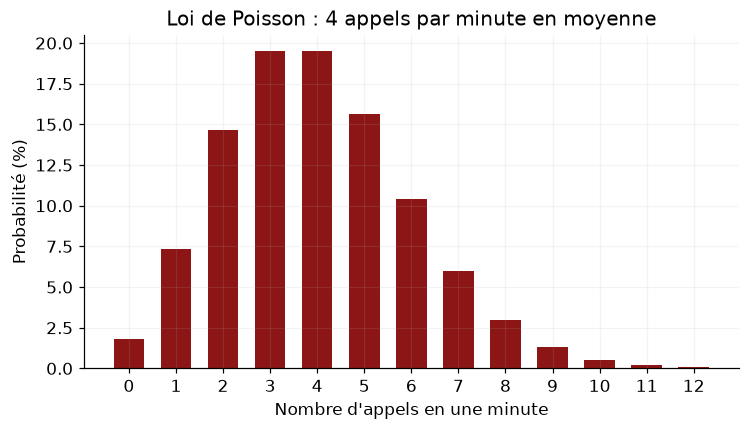

In [14]:
k = np.arange(13)
fig, ax = plt.subplots(figsize=(6.7,3.8))
ax.bar(k,100*loi_appels.pmf(k),width=.65,color=burgundy)
ax.set(title="Loi de Poisson : 4 appels par minute en moyenne",
       xlabel="Nombre d'appels en une minute",ylabel="Probabilité (%)",xticks=k)
plt.show()

### 15. Poisson : un seuil entier et une durée de comptage

poisson utilise mu pour le paramètre lambda. pmf(k)=P(K=k), cdf(k)=P(K≤k), sf(k)=P(K>k). ppf(q) donne le plus petit entier k pour lequel cdf(k)≥q. Attention au décalage : au moins 5 appelle sf(4), pas sf(5). Sur deux minutes, le paramètre vaut 8 si le rythme reste constant.

### 16. Exercice : une capacité qui dépasse rarement

Exercice : écrire le pseudocode et trouver le plus petit entier c tel que loi_appels.sf(c)≤0.01. Utiliser ppf(.99), puis vérifier sf(c) et sf(c-1). Le deuxième contrôle prouve la minimalité. La capacité est un nombre d'appels par minute.

**Votre pseudocode, vos explications et votre trace**

Écrire ici les étapes et une vérification sur un petit cas.

In [15]:
# Votre essai : pseudocode, puis programme et vérification.

### 17. Correction : neuf appels par minute dans ce modèle

Correction : capacité 9 appels/minute. P(K>9)=0.0081322428, soit 0.8132 %. P(K>8)=0.0213634345, soit 2.1363 %. Il s'agit d'une capacité agrégée dans un modèle de comptage, pas d'un dimensionnement complet de centre d'appels.

In [16]:
capacite = int(loi_appels.ppf(0.99))
print(capacite)                         # 9
print(loi_appels.sf(capacite))           # 0.00813...
print(loi_appels.sf(capacite - 1))       # 0.02136...

9
0.008132242796933871
0.021363434487984143


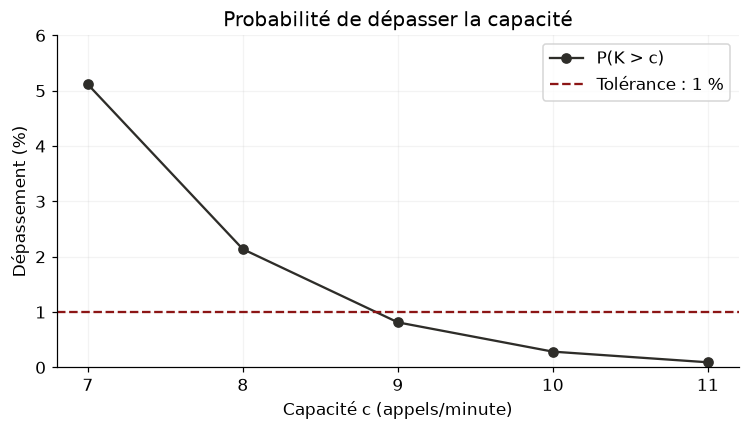

In [17]:
capacites = np.arange(7,12)
fig, ax = plt.subplots(figsize=(6.7,3.8))
ax.plot(capacites,100*loi_appels.sf(capacites),color=ink,marker="o",label="P(K > c)")
ax.axhline(1,color=burgundy,ls="--",label="Tolérance : 1 %")
ax.set(title="Probabilité de dépasser la capacité",
       xlabel="Capacité c (appels/minute)",ylabel="Dépassement (%)",xticks=capacites,ylim=(0,6))
ax.legend()
plt.show()

### 18. Problème 3 : le temps avant le prochain appel

Sous les hypothèses du même processus de Poisson homogène, le temps jusqu'au prochain appel suit une loi exponentielle de taux lambda=4/minute. La survie est P(T>t)=exp(-lambda*t), pour t≥0 en minutes. Sa moyenne vaut 1/lambda=0.25 minute=15 secondes. Il ne s'agit pas d'un rythme déterministe.

$P(T>t)=e^{-4t}$ avec $t$ en minutes. $\mathbb E[T]=1/4$ minute, soit 15 secondes.

### 19. Exercice : trente secondes sans appel

Exercice : loi_attente=stats.expon(scale=1/4), en minutes. 30 s=0.5 minute. Calculer sf(.5), puis ppf(.95) et convertir en secondes. Vérifier exp(-4*.5). scale est la durée moyenne, inverse du taux, contrairement à mu dans la loi de Poisson.

**Votre pseudocode, vos explications et votre trace**

Écrire ici les étapes et une vérification sur un petit cas.

In [18]:
# Votre essai : pseudocode, puis programme et vérification.

### 20. Correction : une aire et une durée

Correction : sf(.5)=exp(-2)=0.13533528. Le quantile à 95 % vaut 0.748933 minute, soit 44.93598 secondes. La densité est une hauteur ; la probabilité est une aire. L'aire après 0.5 continue à l'infini même si le graphique est tronqué à 1.5.

In [19]:
loi_attente = stats.expon(scale=1 / 4)
proba_sans_appel = loi_attente.sf(0.5)
attente_95_secondes = 60 * loi_attente.ppf(0.95)
print(proba_sans_appel)             # 0.135335...
print(attente_95_secondes)          # 44.94 environ

0.1353352832366127
44.93598410330985


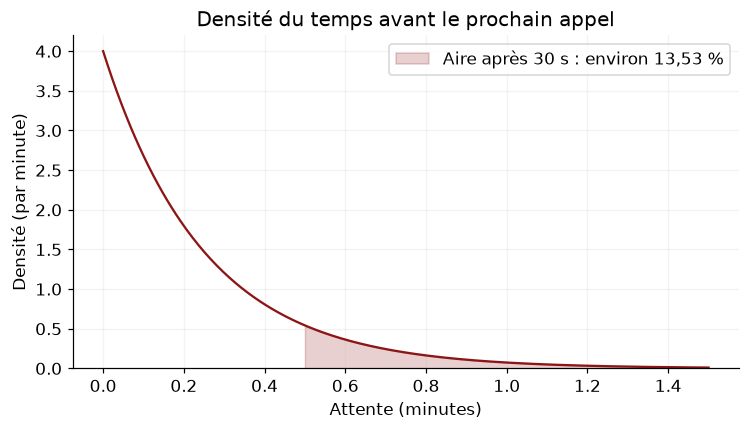

In [20]:
t = np.linspace(0,1.5,400)
fig, ax = plt.subplots(figsize=(6.7,3.8))
ax.plot(t,loi_attente.pdf(t),color=burgundy)
ax.fill_between(t,0,loi_attente.pdf(t),where=t>=.5,color=burgundy,alpha=.2,
    label="Aire après 30 s : environ 13,53 %")
ax.set(title="Densité du temps avant le prochain appel",
       xlabel="Attente (minutes)",ylabel="Densité (par minute)",ylim=(0,4.2))
ax.legend()
plt.show()

### 21. Problème 4 : la moyenne est-elle précise ?

Données : vingt montants [18,21,20,19,22,20,25,17,21,19,23,18,20,22,19,24,18,21,20,23]. Moyenne 20.50 €. On veut estimer l'incertitude de la moyenne de la population. Bootstrap : rééchantillonner avec remise les observations et recalculer la statistique. Hypothèses : observations indépendantes, comparables et représentatives. Le bootstrap ne corrige pas un échantillon biaisé.

Population : toutes les commandes que l’on veut décrire. Échantillon : les vingt commandes observées. On suppose cet échantillon représentatif, avec des observations indépendantes.

In [21]:
montants = np.array([18,21,20,19,22,20,25,17,21,19,
                     23,18,20,22,19,24,18,21,20,23.])

### 22. Le bootstrap, un tirage après l'autre

Démonstration sur quatre observations : rééchantillons [18,18,22,24] moyenne20.5, [20,22,24,24] moyenne22.5, [18,20,20,22] moyenne20.0. Chaque tirage garde la même taille et autorise répétitions et omissions. Les quantiles .025 et .975 des moyennes définissent l'intervalle percentile approximatif à 95 %.

Un percentile est un quantile exprimé en pourcentage : 2,5 % correspond à q=0,025.

| Tirage de quatre valeurs, avec remise | Moyenne |
| --- | --- |
| 18, 18, 22, 24 | 20,50 |
| 20, 22, 24, 24 | 22,50 |
| 18, 20, 20, 22 | 20,00 |

### 23. Exercice : un intervalle avec stats.bootstrap

Reprendre les vingt montants de l'énoncé. Écrire le pseudocode puis utiliser stats.bootstrap pour construire un intervalle percentile à 95 % avec 9 999 rééchantillons et la graine 2026.

- data=(montants,) est un tuple contenant un seul échantillon. La virgule crée le tuple.
- statistic=np.mean transmet la fonction à appliquer, sans l'appeler ici.
- n_resamples fixe le nombre de tirages avec remise.
- confidence_level donne le niveau, method='percentile' la règle de construction.
- vectorized=False applique la fonction séparément à chaque tirage.
- rng fournit le générateur pseudo-aléatoire.

Lire ensuite confidence_interval.low et high. Expliquer ce que l'intervalle estime.

**Votre pseudocode, vos explications et votre trace**

Écrire ici les étapes et une vérification sur un petit cas.

In [22]:
# Votre essai : pseudocode, puis programme et vérification.

### 24. Correction : un intervalle pour la moyenne

Correction : moyenne observée20.5 €, intervalle percentile [19.6,21.45] pour la graine fixée et 9999 rééchantillons. bootstrap_distribution contient les moyennes. Les bornes décrivent l'incertitude de la moyenne de population, pas une plage de valeurs individuelles. L'interprétation fréquentiste porte sur la couverture approximative de la procédure sur des échantillons répétés, pas une probabilité de 95 % d'une moyenne fixe après observation.

In [23]:
resultat = stats.bootstrap(
    (montants,), np.mean, n_resamples=9999,
    confidence_level=0.95, method="percentile",
    vectorized=False, rng=np.random.default_rng(2026))
print(resultat.confidence_interval)  # environ [19.60, 21.45]

ConfidenceInterval(low=np.float64(19.6), high=np.float64(21.45))


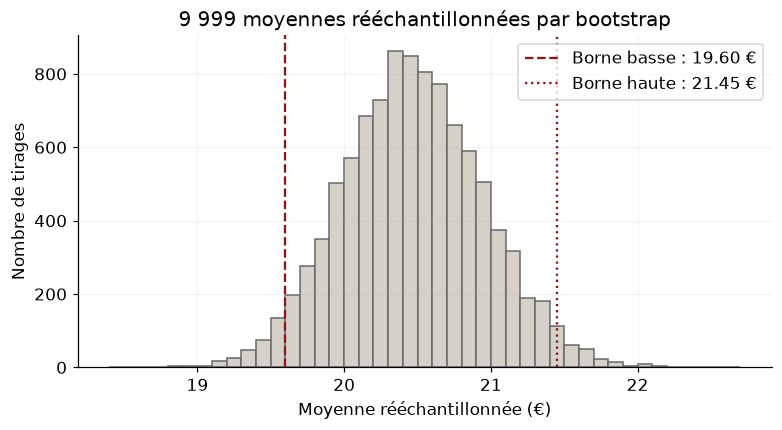

In [24]:
moyennes_bootstrap = resultat.bootstrap_distribution
borne_basse = resultat.confidence_interval.low
borne_haute = resultat.confidence_interval.high
fig, ax = plt.subplots(figsize=(7,3.8))
ax.hist(moyennes_bootstrap,bins=np.arange(18.4,22.71,.1),color="#D5D0C8",edgecolor=slate)
ax.axvline(borne_basse,color=burgundy,ls="--",label=f"Borne basse : {borne_basse:.2f} €")
ax.axvline(borne_haute,color=burgundy,ls=":",label=f"Borne haute : {borne_haute:.2f} €")
ax.set(title="9 999 moyennes rééchantillonnées par bootstrap",
       xlabel="Moyenne rééchantillonnée (€)",ylabel="Nombre de tirages")
ax.legend()
plt.show()

Interprétation : en répétant l'échantillonnage et cette procédure dans des conditions adaptées, la proportion d'intervalles qui couvrent la moyenne de la population est approximativement de 95 %. Le niveau ne signifie pas que 95 % des commandes coûtent entre ces bornes. Augmenter le nombre de rééchantillons stabilise le calcul, sans créer de nouvelles observations réelles.

## 2. Concurrence et parallélisme

### 25. Calculer ou attendre : deux situations différentes

Une opération peut calculer ou attendre une entrée-sortie. En séquentiel, l'attente de B commence après celle de A. En concurrence, les attentes peuvent se chevaucher. Parallélisme : exécution simultanée de calculs sur plusieurs unités. Le chevauchement des attentes suffit souvent à réduire la durée totale.

### 26. Threads et processus : qui partage quoi ?

Un processus est un programme en cours d'exécution, avec sa mémoire. Plusieurs threads peuvent exister dans le même processus et partager ses variables. Les processus ont des mémoires séparées. Le parent envoie les arguments aux enfants et reçoit leurs résultats.

### 27. Un exemple d'attente, sans connexion réseau

lire_capteur(numero) attend environ 0,2 seconde puis renvoie numero*10. sleep bloque le thread courant. perf_counter sert à mesurer une durée par différence entre deux lectures. Le programme simule trois appareils localement.

In [25]:
from time import sleep, perf_counter
def lire_capteur(numero):
    sleep(0.2)
    return numero * 10
print(lire_capteur(1))  # attend environ 0,2 s, puis renvoie 10

10


### 28. Un pool de threads : réutiliser des travailleurs

ThreadPoolExecutor gère des threads réutilisables. map applique la fonction à chaque argument, list récupère les résultats dans l'ordre fourni, même si l'ordre de fin varie. with attend les travaux et ferme le pool. max_workers=3 autorise au maximum trois appels simultanés.

In [26]:
from concurrent.futures import ThreadPoolExecutor
debut = perf_counter()
with ThreadPoolExecutor(max_workers=3) as pool:
    reponses_threads = list(pool.map(lire_capteur, [1, 2, 3]))
duree_threads = perf_counter() - debut
print(reponses_threads)  # [10, 20, 30]

[10, 20, 30]


### 29. Exercice : prévoir les réponses et les attentes

Chaque appel attend 0,2 s. Prévoir les réponses et tracer les attentes en séquentiel et avec trois threads. Prévoir puis mesurer les durées avec perf_counter.

**Votre démarche et votre trace**

Écrire ici les étapes, les valeurs attendues et la vérification à la main.

**Code à analyser**

~~~python
reponses = []
for numero in [1, 2, 3]:
    reponses.append(lire_capteur(numero))
~~~

In [27]:
# Votre essai : pseudocode, puis code ou correction.

### 30. Correction : les mêmes valeurs, des attentes superposées

Les deux listes valent [10,20,30]. Modèle idéal : 0,6 seconde en séquentiel et 0,2 avec trois threads. Les durées réelles incluent les frais de gestion. On chevauche des attentes, sans supposer que trois boucles Python de calcul deviendraient trois fois plus rapides.

In [28]:
debut = perf_counter()
reponses_seq = [lire_capteur(n) for n in [1, 2, 3]]
duree_seq = perf_counter() - debut
print(round(duree_seq, 3), round(duree_threads, 3))

0.61 0.208


### 31. Plusieurs processus pour des calculs indépendants

somme_carres(n) parcourt range(n), de 0 à n-1. Pour 4 : 14. Pour 5 : 30. Chaque processus calcule une somme sans modifier les données des autres. La fonction est fournie dans un module importable ; la cellule du notebook lance un script autonome.

**Programme fourni**

~~~python
# Fichier ch06_travailleurs.py fourni
def somme_carres(n):
    total = 0
    for i in range(n):
        total += i * i
    return total
~~~

### 32. Le programme qui lance les processus

Le programme autonome importe somme_carres depuis ch06_travailleurs.py. spawn démarre de nouveaux interpréteurs. La garde `__name__ == '__main__'` réserve le lancement du pool à l'exécution directe du fichier. map et list ont le même rôle qu'avec les threads. Résultats : [14,30].

**Programme fourni**

~~~python
from concurrent.futures import ProcessPoolExecutor
from multiprocessing import get_context
from ch06_travailleurs import somme_carres
if __name__ == "__main__":
    with ProcessPoolExecutor(
        max_workers=2, mp_context=get_context("spawn")
    ) as pool:
        resultats = list(pool.map(somme_carres, [4, 5]))
    print(resultats)  # [14, 30]
~~~

**Lancement fourni**

La cellule suivante écrit les deux fichiers dans un dossier temporaire et lance un Python autonome. Les enfants peuvent ainsi importer la fonction. La préparation est fournie.

In [29]:
from pathlib import Path
from tempfile import TemporaryDirectory
import subprocess, sys

module_fourni = '"""Fonction importable par les processus du chapitre 6."""\n\ndef somme_carres(n):\n    total = 0\n    for i in range(n):\n        total += i * i\n    return total\n\n'
programme_fourni = '"""Comparer les mêmes sommes en séquentiel et dans deux processus."""\nfrom concurrent.futures import ProcessPoolExecutor\nfrom multiprocessing import get_context\nfrom time import perf_counter\nfrom ch06_travailleurs import somme_carres\n\n\ndef comparer(tailles):\n    debut = perf_counter()\n    reference = [somme_carres(n) for n in tailles]\n    duree_seq = perf_counter() - debut\n\n    debut = perf_counter()\n    with ProcessPoolExecutor(\n            max_workers=2, mp_context=get_context("spawn")) as pool:\n        lots = list(pool.map(somme_carres, tailles))\n    duree_processus = perf_counter() - debut\n\n    assert lots == reference\n    print("Tailles :", tailles)\n    print("Resultats :", lots)\n    print("Resultats identiques :", lots == reference)\n    print("Secondes, sequentiel :", round(duree_seq, 4))\n    print("Secondes, processus :", round(duree_processus, 4))\n    print("Les temps incluent le demarrage et les echanges du pool.")\n\n\nif __name__ == "__main__":\n    comparer([4, 5])\n    comparer([3_000_000, 4_000_000])\n    print("Un gain de temps n\'est pas garanti.")\n'

with TemporaryDirectory(prefix="cours_ch06_") as dossier:
    chemin = Path(dossier)
    (chemin/"ch06_travailleurs.py").write_text(module_fourni, encoding="utf-8")
    script = chemin/"chapitre_06_processus.py"
    script.write_text(programme_fourni, encoding="utf-8")
    execution = subprocess.run([sys.executable, str(script)], cwd=chemin,
        text=True, capture_output=True, check=True, timeout=60)
    print(execution.stdout)

Tailles : [4, 5]
Resultats : [14, 30]
Resultats identiques : True
Secondes, sequentiel : 0.0
Secondes, processus : 0.0366
Les temps incluent le demarrage et les echanges du pool.
Tailles : [3000000, 4000000]
Resultats : [8999995500000500000, 21333325333334000000]
Resultats identiques : True
Secondes, sequentiel : 0.1548
Secondes, processus : 0.1198
Les temps incluent le demarrage et les echanges du pool.
Un gain de temps n'est pas garanti.



### 33. Le coût du démarrage et le rôle du GIL

Comparer les mêmes sommes pour [4,5], puis pour deux grands n, en séquentiel et avec deux processus. Mesurer le démarrage, les échanges et le calcul ensemble. Expliquer les durées observées.

**Votre démarche et votre trace**

Écrire ici les étapes, les valeurs attendues et la vérification à la main.

In [30]:
# Votre essai : pseudocode, puis code ou correction.

### 34. Une coroutine : un calcul qui peut se suspendre

asyncio est une bibliothèque Python qui organise plusieurs opérations pouvant attendre. Une coroutine est une exécution capable de se suspendre et de reprendre en conservant son état. async def définit une fonction coroutine. Appeler lire_async(1) crée un objet coroutine sans exécuter le corps. await lire_async(1) dans le notebook exécute et attend le résultat. Toujours attendre ou planifier une coroutine créée.

In [31]:
import asyncio
async def lire_async(numero):
    await asyncio.sleep(0.2)
    return numero * 10

In [32]:
premiere_reponse = await lire_async(1)
print(premiere_reponse)

10


### 35. await : suspendre l'opération en cours

await attend une opération compatible. Si cette opération doit attendre, la tâche courante se suspend ; la boucle d'événements peut exécuter d'autres tâches prêtes dans le même thread. Quand le délai finit, la coroutine reprend après await. await ne lance pas automatiquement un nouveau thread et ne garantit pas une suspension si le résultat est déjà disponible.

### 36. Une tâche : une coroutine prise en charge par asyncio

Une tâche Task planifie et suit une coroutine. gather planifie automatiquement les coroutines reçues comme des tâches, puis attend leur ensemble. Les résultats respectent l'ordre des arguments. Dans Jupyter, utiliser await lectures(); dans un script sans boucle active, asyncio.run(lectures()). create_task permet une création explicite, mais gather suffit dans cet exemple.

In [33]:
async def lectures():
    return await asyncio.gather(
        lire_async(1),
        lire_async(2),
        lire_async(3)
    )

In [34]:
print(await lectures())

[10, 20, 30]


### 37. Exercice : deux await successifs ou gather ?

Comparer les await successifs à gather : prévoir les listes, tracer les attentes, puis mesurer. Que changerait sleep(0.2) à la place de await asyncio.sleep(0.2) ?

**Votre démarche et votre trace**

Écrire ici les étapes, les valeurs attendues et la vérification à la main.

**Code à analyser**

~~~python
async def lune_apres_lautre():
    a = await lire_async(1)
    b = await lire_async(2)
    return [a, b]

async def ensemble():
    return await asyncio.gather(lire_async(1), lire_async(2))
~~~

In [35]:
# Votre essai : pseudocode, puis code ou correction.

### 38. Correction : async ne suffit pas à chevaucher les attentes

Les deux versions renvoient [10,20]. Deux await successifs prennent environ 0,4 seconde. gather peut approcher 0,2 seconde plus les frais de gestion. sleep bloque le thread courant ; asyncio.sleep suspend la tâche, permettant d'autres tâches. Le notebook mesure les deux versions.

In [36]:
async def ensemble():
    return await asyncio.gather(lire_async(1), lire_async(2))

In [37]:
async def lune_apres_lautre():
    a = await lire_async(1)
    b = await lire_async(2)
    return [a, b]
debut = perf_counter()
resultats_successifs = await lune_apres_lautre()
temps_successifs = perf_counter() - debut
debut = perf_counter()
resultats_async = await ensemble()
temps_async = perf_counter() - debut
print(resultats_successifs, resultats_async)
print("Secondes, successifs :", round(temps_successifs,3))
print("Secondes, gather :", round(temps_async,3))

[10, 20] [10, 20]
Secondes, successifs : 0.403
Secondes, gather : 0.202


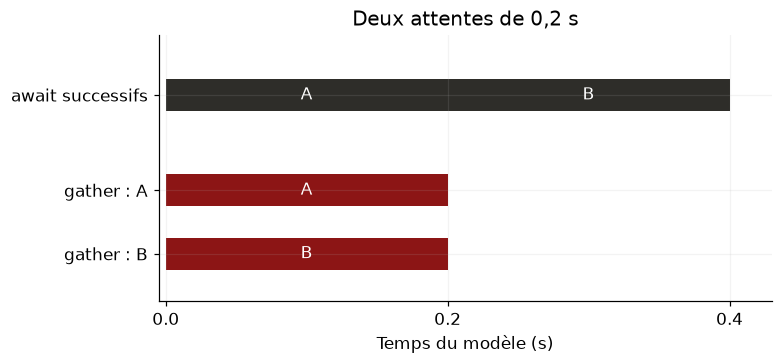

In [38]:
fig, ax = plt.subplots(figsize=(7,3.2))
for debut_segment,ligne,nom,couleur in [
    (0,3,"A",ink),(.2,3,"B",ink),(0,1.5,"A",burgundy),(0,.5,"B",burgundy)]:
    ax.broken_barh([(debut_segment,.2)],(ligne,.5),facecolors=couleur)
    ax.text(debut_segment+.1,ligne+.25,nom,color="white",ha="center",va="center")
ax.set(yticks=[3.25,1.75,.75],yticklabels=["await successifs","gather : A","gather : B"],
    xticks=[0,.2,.4],xlim=(-.005,.43),ylim=(0,4.2),
    xlabel="Temps du modèle (s)",title="Deux attentes de 0,2 s")
plt.show()

### 39. Donnée partagée : une mise à jour peut se perdre

A et B veulent ajouter chacun 1 au compteur 10. Chacun lit avant la première écriture. Tracer les lectures, calculs et écritures. Quelle séquence faut-il protéger ?

**Votre démarche et votre trace**

Écrire ici les étapes, les valeurs attendues et la vérification à la main.

In [39]:
# Votre essai : pseudocode, puis code ou correction.

### 40. Un verrou protège la séquence complète

Lock protège la séquence entière de lecture puis d'écriture. with verrou acquiert et libère le verrou, même si une erreur sort du bloc. Les dix appels du pool ajoutent chacun un, résultat 10. L'argument _ est une convention pour un argument inutilisé.

In [40]:
from threading import Lock
verrou = Lock()
etat = {"total": 0}
def ajouter(_):
    with verrou:
        ancien = etat["total"]
        etat["total"] = ancien + 1

with ThreadPoolExecutor(max_workers=2) as pool:
    list(pool.map(ajouter, range(10)))
print(etat["total"])  # 10

10


### 41. Deadlock : chacun attend une ressource de l'autre

A détient V1 et attend V2 ; B détient V2 et attend V1. Expliquer le blocage et proposer un ordre commun d'acquisition. Ne pas exécuter un programme bloqué.

**Votre démarche et votre trace**

Écrire ici les étapes, les valeurs attendues et la vérification à la main.

In [41]:
# Votre essai : pseudocode, puis code ou correction.

### 42. Correction : tous prennent V1 avant V2

Correction : imposer V1 puis V2 partout. Quand A détient V1, B attend V1 sans garder V2. A peut donc prendre V2 puis terminer. Résultats A termine et B termine. Le résultat de map garde l'ordre A,B.

In [42]:
v1, v2 = Lock(), Lock()
def operation(nom):
    with v1:
        with v2:
            return nom + " termine"

with ThreadPoolExecutor(max_workers=2) as pool:
    print(list(pool.map(operation, ["A", "B"])))

['A termine', 'B termine']


### 43. Livelock : bouger sans réussir à passer

Deux personnes sont dans la même moitié du couloir et changent toutes deux de moitié à chaque tour. Dessiner trois tours, puis proposer une règle leur permettant de se croiser.

**Votre démarche et votre trace**

Écrire ici les étapes, les valeurs attendues et la vérification à la main.

In [43]:
# Votre essai : pseudocode, puis code ou correction.

### 44. Une priorité permet de sortir du blocage actif

Dans le modèle, A garde sa moitié et B change une seule fois : les deux peuvent passer. Deadlock : attente bloquante circulaire. Livelock : activité sans progrès. Famine : une opération n'obtient jamais les ressources ou son tour. Ces situations sont distinctes.

### 45. Choisir selon le travail à effectuer

Repères : formule sur des valeurs numériques, NumPy ; plusieurs I/O bloquantes, threads ; longs calculs Python indépendants, processus ; API asynchrone, asyncio. Il faut une opération compatible avec await. Toujours comparer les résultats et la durée complète.

## 3. Premières tables pandas

### 46. Deuxième partie : une table de commandes

Le jeu complet contient huit commandes. Une ligne représente une commande, les prix sont en euros et les délais en jours. Les valeurs manquantes sont intentionnelles.

### 47. DataFrame, Series et index

Un DataFrame est une table, une Series une suite étiquetée, par exemple une colonne. L'index 0,1,2 n'est pas le numéro de commande 101,102,103. Le dictionnaire de construction associe les noms aux colonnes, toutes de même longueur. np.nan représente une donnée numérique absente. La table complète est fournie.

In [44]:
import pandas as pd
commandes = pd.DataFrame({
    "id": [101, 102, 103, 104, 105, 106, 107, 108],
    "ville": ["Tunis", "Sfax", "Tunis", "Sfax",
              "Tunis", "Sousse", "Sousse", "Sfax"],
    "quantite": [2, 1, 3, np.nan, 1, 2, 1, 4],
    "prix": [10., 20., 10., 20., 15., 12., 12., 20.],
    "delai": [2., 3., np.nan, 4., 2., 5., np.nan, 3.]
})

In [45]:
import pandas as pd
villes = commandes["ville"]
print(villes)

0     Tunis
1      Sfax
2     Tunis
3      Sfax
4     Tunis
5    Sousse
6    Sousse
7      Sfax
Name: ville, dtype: object


### 48. Examiner une table avant de calculer

La table contient huit lignes et cinq colonnes, une quantité absente et deux délais absents. Les huit identifiants sont uniques.

In [46]:
print(commandes.head(4))       # premières lignes
print(commandes.shape)         # (8, 5)
print(commandes.dtypes)        # type par colonne
print(commandes.isna().sum())  # absences par colonne
print(commandes["id"].is_unique)

    id  ville  quantite  prix  delai
0  101  Tunis       2.0  10.0    2.0
1  102   Sfax       1.0  20.0    3.0
2  103  Tunis       3.0  10.0    NaN
3  104   Sfax       NaN  20.0    4.0
(8, 5)
id            int64
ville        object
quantite    float64
prix        float64
delai       float64
dtype: object
id          0
ville       0
quantite    1
prix        0
delai       2
dtype: int64
True


### 49. Sélectionner par étiquette ou par position

loc utilise des étiquettes ou un masque, iloc des positions. Avec l'index initial, les deux coïncident pour la ligne 0. Après filtrage, ce n'est plus garanti. loc[masque,['id','ville']] conserve les lignes où le masque est True et seulement ces deux colonnes.

In [47]:
print(commandes.loc[0, "ville"])  # Tunis : étiquette 0
print(commandes.iloc[0, 1])       # Tunis : position (0, 1)
est_tunis = commandes["ville"] == "Tunis"
print(commandes.loc[est_tunis, ["id", "ville"]])

Tunis
Tunis
    id  ville
0  101  Tunis
2  103  Tunis
4  105  Tunis


### 50. Exercice : calculer et filtrer des montants

Créer montant=quantite*prix, puis sélectionner les commandes de Tunis de montant >= 20 €. Écrire le pseudocode puis le code, et vérifier les lignes retenues à la main.

**Votre démarche et votre trace**

Écrire ici les étapes, les valeurs attendues et la vérification à la main.

In [48]:
# Votre essai : pseudocode, puis code ou correction.

### 51. Correction : calculer une colonne, puis sélectionner

Deux commandes répondent aux conditions : 101 pour 20 euros et 103 pour 30 euros. Leur somme vaut 50 euros.

In [49]:
commandes["montant"] = commandes["quantite"] * commandes["prix"]
masque = ((commandes["ville"] == "Tunis")
          & (commandes["montant"] >= 20))
selection = commandes.loc[masque, ["id", "ville", "montant"]]
print(selection)
# id 101 : 20 euros ; id 103 : 30 euros

    id  ville  montant
0  101  Tunis     20.0
2  103  Tunis     30.0


### 52. Débogage : modifier une sélection

Corriger le délai de la commande 103 à 4 jours, dans une copie corrigees. Remplacer l'affectation en deux sélections par une unique affectation loc.

**Votre démarche et votre trace**

Écrire ici les étapes, les valeurs attendues et la vérification à la main.

In [50]:
# Votre essai : pseudocode, puis code ou correction.

### 53. Correction : une affectation explicite

La commande 103 a un délai corrigé de 4 jours dans corrigees. La table commandes reste la référence d'origine pour la suite.

In [51]:
corrigees = commandes.copy()
masque_103 = corrigees["id"] == 103
corrigees.loc[masque_103, "delai"] = 4
print(corrigees.loc[masque_103, ["id", "delai"]])

    id  delai
2  103    4.0


### 54. Deux absences, deux décisions différentes

La politique choisie garde les commandes dont la quantité est connue. Un délai absent n'empêche pas le calcul du chiffre d'affaires. Le nombre d'observations utilisé pour chaque mesure doit être explicite.

### 55. Exercice : conserver les commandes exploitables

Écarter seulement les lignes sans quantité. Conserver les délais absents, sans les remplacer par zéro. Calculer le nombre de lignes valides, les délais présents et absents, puis le CA observé.

**Votre démarche et votre trace**

Écrire ici les étapes, les valeurs attendues et la vérification à la main.

In [52]:
# Votre essai : pseudocode, puis code ou correction.

### 56. Correction : un total et son périmètre

Le chiffre d'affaires observé est 201 euros pour sept commandes. Cinq délais sont observés. Le résultat n'est pas le chiffre d'affaires de toutes les commandes.

In [53]:
valides = commandes.dropna(subset=["quantite"]).copy()
print(len(commandes) - len(valides))  # 1 ligne écartée
print(valides["delai"].isna().sum())  # 2 délais absents
print(valides["montant"].sum())      # 201 euros
print(valides["delai"].count())      # 5 délais observés

1
2
201.0
5


### 57. Regrouper les commandes par ville

groupby('ville') rassemble les lignes par ville. Sélectionner montant puis sum calcule le CA de chaque groupe : Tunis65, Sfax100, Sousse36. agg permet plusieurs résultats en nommant chaque colonne de sortie par un couple (colonne source, calcul).

Calculs : sum = somme, mean = moyenne, size = nombre de lignes, count = nombre de valeurs présentes.

In [54]:
ca_ville = valides.groupby("ville")["montant"].sum()
print(ca_ville)

ville
Sfax      100.0
Sousse     36.0
Tunis      65.0
Name: montant, dtype: float64


### 58. Exercice : résumer les ventes par ville

Résumer par ville : nombre de commandes, CA, délai moyen et nombre de délais observés. Expliquer size et count et vérifier un groupe à la main.

**Votre démarche et votre trace**

Écrire ici les étapes, les valeurs attendues et la vérification à la main.

In [55]:
# Votre essai : pseudocode, puis code ou correction.

### 59. Correction : des résumés avec leurs effectifs

Sfax : 100 euros ; Sousse : 36 ; Tunis : 65. Les délais sont calculés sur 2, 1 et 2 valeurs respectivement. La moyenne de Sousse repose sur une seule mesure.

In [56]:
resume = valides.groupby("ville", as_index=False).agg(
    n_commandes=("id", "size"), ca=("montant", "sum"),
    delai_moyen=("delai", "mean"), n_delais=("delai", "count"))
print(resume)
print(resume.sort_values("ca", ascending=False))

    ville  n_commandes     ca  delai_moyen  n_delais
0    Sfax            2  100.0          3.0         2
1  Sousse            2   36.0          5.0         1
2   Tunis            3   65.0          2.0         2
    ville  n_commandes     ca  delai_moyen  n_delais
0    Sfax            2  100.0          3.0         2
2   Tunis            3   65.0          2.0         2
1  Sousse            2   36.0          5.0         1


## Compléments pandas

Ces exercices prolongent les 59 diapositives. Ils peuvent être repris à la séance suivante.

### Complément pandas · Débogage : pandas aligne les étiquettes

Prévoir prix*quantites avec les étiquettes A,B et B,A. Prévoir le résultat après to_numpy. Dessiner les paires effectivement multipliées.

**Votre démarche et votre trace**

Écrire ici les étapes, les valeurs attendues et la vérification à la main.

**Code à analyser**

~~~python
prix = pd.Series([10, 20], index=["A", "B"])
quantites = pd.Series([3, 2], index=["B", "A"])
print(prix * quantites)
print(prix.to_numpy() * quantites.to_numpy())
~~~

In [57]:
# Votre essai : pseudocode, puis code ou correction.

### Complément pandas · Correction : étiquettes ou positions

Les bonnes valeurs sont A : 20 et B : 60. Le calcul par position sans alignement préalable donne [30,40], ce qui associe les mauvais produits.

In [58]:
prix = pd.Series([10, 20], index=["A", "B"])
quantites = pd.Series([3, 2], index=["B", "A"])
print(prix * quantites)  # A : 20 ; B : 60
print(prix.to_numpy() * quantites.to_numpy())  # [30 40]
q_alignees = quantites.reindex(prix.index)
print(prix.to_numpy() * q_alignees.to_numpy())  # [20 60]

A    20
B    60
dtype: int64
[30 40]
[20 60]


### Complément pandas · Lire un CSV et convertir des colonnes

Le notebook fournit aussi le contenu du CSV en mémoire pour rester autonome. Le fichier du pack contient exactement les mêmes données. Une conversion impossible devient manquante et doit être auditée.

StringIO lit un texte comme un fichier. Pour lire le CSV sur disque, remplacer StringIO(contenu_csv) par son chemin.

In [59]:
from io import StringIO
contenu_csv = """id;date;ville;quantite;prix;delai
101;2026-10-01;Tunis;2;10;2
102;2026-10-01;Sfax;1;20;3
103;2026-10-02;Tunis;3;10;
104;2026-10-02;Sfax;;20;4
105;2026-10-03;Tunis;1;15;2
106;2026-10-03;Sousse;2;12;5
107;2026-10-04;Sousse;1;12;
108;2026-10-04;Sfax;4;20;3
"""
table = pd.read_csv(StringIO(contenu_csv),sep=";")
table["date"] = pd.to_datetime(table["date"],errors="coerce")
table["quantite"] = pd.to_numeric(table["quantite"],errors="coerce")
print(table.head(3))

    id       date  ville  quantite  prix  delai
0  101 2026-10-01  Tunis       2.0    10    2.0
1  102 2026-10-01   Sfax       1.0    20    3.0
2  103 2026-10-02  Tunis       3.0    10    NaN


### Complément pandas · Exercice final : appliquer une remise et résumer

Accorder 10 % de remise si quantite >= 3. Écrire le pseudocode puis calculer les montants nets avec np.where, le total et les totaux par ville. Vérifier les deux lignes remisées à la main.

**Votre démarche et votre trace**

Écrire ici les étapes, les valeurs attendues et la vérification à la main.

In [60]:
# Votre essai : pseudocode, puis code ou correction.

### Complément pandas · Correction : NumPy calcule, pandas organise

Les montants nets par ville sont 92, 36 et 62 euros. Leur somme vaut 190 euros. Les deux remises totalisent 11 euros.

In [61]:
coefficients = np.where(valides["quantite"] >= 3, 0.9, 1.)
valides["net"] = valides["montant"] * coefficients
nets_ville = valides.groupby("ville", as_index=False).agg(
    net=("net", "sum"))
print(nets_ville)           # Sfax 92 ; Sousse 36 ; Tunis 62
print(valides["net"].sum())  # 190 euros
print((valides["montant"] - valides["net"]).sum())  # 11

    ville   net
0    Sfax  92.0
1  Sousse  36.0
2   Tunis  62.0
190.0
11.0


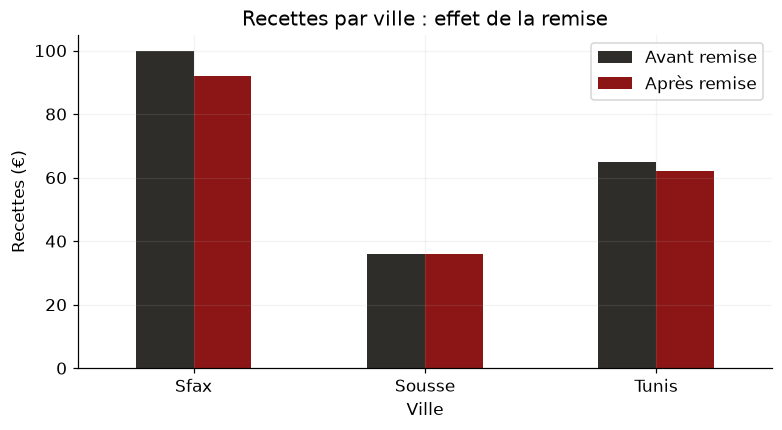

In [62]:
comparaison = valides.groupby("ville")[["montant","net"]].sum()
ax = comparaison.plot.bar(figsize=(7,3.8),color=[ink,burgundy],rot=0)
ax.set(title="Recettes par ville : effet de la remise",xlabel="Ville",ylabel="Recettes (€)")
ax.legend(["Avant remise","Après remise"])
plt.show()

### Complément pandas · Repères pour résoudre les prochains problèmes



Avant le code : préciser les entrées, les sorties et les unités, écrire les étapes et vérifier un petit cas. Après le code : contrôler les formes, les résultats et, si besoin, mesurer la durée complète.

## Références des nouveaux calculs

- [NumPy : cumprod](https://numpy.org/doc/stable/reference/generated/numpy.cumprod.html)
- [NumPy : searchsorted](https://numpy.org/doc/stable/reference/generated/numpy.searchsorted.html)
- [NumPy : quantile](https://numpy.org/doc/stable/reference/generated/numpy.quantile.html)
- [SciPy : Poisson](https://docs.scipy.org/doc/scipy/reference/generated/scipy.stats.poisson.html)
- [SciPy : exponentielle](https://docs.scipy.org/doc/scipy/reference/generated/scipy.stats.expon.html)
- [SciPy : bootstrap](https://docs.scipy.org/doc/scipy/reference/generated/scipy.stats.bootstrap.html)